# Зарплатные сегменты · копия с проверками распределений

Копия исходного [ноутбука зарплатного исследования](salary_segment_suitability_final.ipynb).
Дополнение в конце проверяет форму распределений и выводы по утверждённым сегментам
на том же снимке, что исходное зарплатное исследование и паспорта 15 ячеек.
Исходные таблицы рейтинга при запуске копии выгружаются во временную папку.

Новые результаты находятся в разделах 6–7 в конце ноутбука. `normaltest_p` и
`normal_like` в исходном рейтинге относятся к предыдущей диагностике.

Для повторного запуска нужен полный Git-клон. Откройте ноутбук из `Analytics/`
или из корня репозитория. Расчёт выполнен на pandas 2.3.3, NumPy 2.3.3,
SciPy 1.18.1 и statsmodels 0.14.6. Также требуются Jupyter, matplotlib, Jinja2 и tabulate.

# Пригодность зарплатных сегментов для моделирования

Финальная доработка исследования Ярослава Ознобихина и Павла Шелепчикова.

Ноутбук закрывает критерии карточки Buildin:

- расчёты только по `profession_resolved × city_resolved`;
- исходные суммы, закрытые вилки и односторонние границы учитываются раздельно;
- неизвестный период не считается месячным;
- основной рейтинг исключает вахту, удалённую работу и `military=True`;
- вахта и удалённая работа исследуются отдельно;
- показаны охват и ограничения нормализации;
- рассчитывается рейтинг сегментов, список кандидатов на добор и параметризованный профиль сегмента;
- «в рынке» задаётся эмпирическим интервалом Q1–Q3, а не предположением о нормальности.

### Что было в первичном ноутбуке Паши

Сильная основа: парсер форматов, раздельные единицы оплаты и налоговая база, Q10/медиана/Q90, первые сценарии пересчёта. В этой версии исправлены главные ограничения: `from/to` больше не превращаются в точечные зарплаты, середина вилки явно помечена как аналитический показатель, `unspecified` не переименовывается в месяц, добавлены устойчивость, концентрация работодателей, нормальность, рейтинг, добор и отдельные профили вахты/удалёнки.

In [1]:
from pathlib import Path
import hashlib
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"

from pathlib import Path
import sys

analytics = Path("Analytics") if Path("Analytics").is_dir() else Path.cwd()
sys.path.insert(0, str(analytics.resolve()))

from segment_normality import (
    ALPHA, MIN_TEST_N, PRIORITY, REJECT, SEGMENT_KEYS,
    holm, lilliefors_row, load_snapshot, priority_vacancies,
)

from tempfile import TemporaryDirectory

ratings_dir = TemporaryDirectory(prefix="tl-salary-ratings-")
OUTPUT_DIR = Path(ratings_dir.name)
RANDOM_STATE = 42

raw, dataset_source, dataset_hash = load_snapshot("decision")

print(f"Файл: {dataset_source}")
print(f"Строки × столбцы: {raw.shape}")
print(f"SHA-256: {dataset_hash}")

required = {"source", "id", "salary_raw", "profession_resolved", "city_resolved"}
missing = sorted(required - set(raw.columns))
assert not missing, f"Нет обязательных колонок: {missing}"

df = raw.drop_duplicates(["source", "id"], keep="last").copy()
print(f"После дедупликации source × id: {len(df):,}")

Файл: 7450447f481931cb62cef837c52d21216e53b83c:Data/dataset/vacancies.csv
Строки × столбцы: (23036, 127)
SHA-256: 835f5ac1c0ba1770d7fdd0718261f3445bff11acec653c795daa3c250d4e29d7
После дедупликации source × id: 23,036


## 1. Парсинг опубликованной зарплаты и когорты

`exact` означает одну опубликованную сумму. `range` означает закрытую вилку; для описания её положения используется midpoint, но он не объявляется наблюдаемой фактической зарплатой. `from` и `to` сохраняются как цензурированные границы и не входят в точечные распределения.

In [2]:
SALARY_RE = re.compile(
    r"(?:(от|до)\s+)?"
    r"(\d[\d\s ]*)"
    r"(?:\s*[—–-]\s*(\d[\d\s ]*))?"
    r"\s*₽"
    r"(?:\s+(за смену|в час|за час|в неделю|за неделю|за день|в день|в месяц|за месяц|сдельно))?"
    r"(?:\s+(на руки|до вычета налогов))?",
    re.IGNORECASE,
)

UNITS = {
    "за смену": "shift", "в час": "hour", "за час": "hour",
    "в неделю": "week", "за неделю": "week", "за день": "day",
    "в день": "day", "в месяц": "month", "за месяц": "month",
    "сдельно": "piecework",
}

def parse_salary(value):
    result = dict(
        salary_min_rub=np.nan, salary_max_rub=np.nan,
        salary_unit="unspecified", salary_tax="unknown",
        salary_shape="unknown", salary_parse_status="unrecognized",
    )
    if pd.isna(value):
        result["salary_parse_status"] = "missing"
        return result
    text = re.sub(r"\s+", " ", str(value).replace("﻿", " ")).strip()
    if not text or text.casefold() == "зарплата не указана":
        result["salary_parse_status"] = "missing"
        return result
    match = SALARY_RE.fullmatch(text)
    if match is None:
        return result
    bound, first, second, unit, tax = match.groups()
    first = float(re.sub(r"\D", "", first))
    second = float(re.sub(r"\D", "", second)) if second else np.nan
    unit_key = unit.casefold() if unit else None
    result["salary_unit"] = UNITS.get(unit_key, "unspecified")
    result["salary_tax"] = {"на руки": "net", "до вычета налогов": "gross"}.get(
        tax.casefold() if tax else None, "unknown"
    )
    if second == second:
        result.update(salary_min_rub=min(first, second), salary_max_rub=max(first, second), salary_shape="range")
    elif bound and bound.casefold() == "от":
        result.update(salary_min_rub=first, salary_shape="from")
    elif bound and bound.casefold() == "до":
        result.update(salary_max_rub=first, salary_shape="to")
    else:
        result.update(salary_min_rub=first, salary_max_rub=first, salary_shape="exact")
    result["salary_parse_status"] = "parsed"
    return result

parsed = df["salary_raw"].apply(parse_salary).apply(pd.Series)
df = pd.concat([df, parsed], axis=1)
df["salary_midpoint_rub"] = np.where(
    df["salary_shape"].isin(["exact", "range"]),
    (df["salary_min_rub"] + df["salary_max_rub"]) / 2,
    np.nan,
)

def text_contains(col, pattern):
    return df.get(col, pd.Series("", index=df.index)).astype("string").fillna("").str.contains(pattern, case=False, regex=True)

df["is_vahta"] = text_contains("График", "вахт") | text_contains("title", "вахт")
df["is_remote"] = text_contains("Формат работы", "удал") | text_contains("run_id", "remote")
military_raw = df.get("military", pd.Series(False, index=df.index))
df["is_military"] = military_raw.fillna(False).astype(str).str.casefold().isin(["true", "1", "да", "yes"])

cohort_counts = pd.Series({
    "Все уникальные вакансии": len(df),
    "Вахта": int(df["is_vahta"].sum()),
    "Удалённая работа": int(df["is_remote"].sum()),
    "Military": int(df["is_military"].sum()),
    "Основная когорта": int((~df[["is_vahta", "is_remote", "is_military"]].any(axis=1)).sum()),
}).rename("n").to_frame()
display(cohort_counts)

,n
Все уникальные вакансии,23036
Вахта,4694
Удалённая работа,3064
Military,315
Основная когорта,15185


,salary_parse_status,salary_unit,salary_tax,salary_shape,n,share_all
27,parsed,unspecified,net,range,4993,21.7%
26,parsed,unspecified,net,from,3697,16.0%
31,parsed,unspecified,unknown,range,3150,13.7%
18,parsed,shift,net,from,2046,8.9%
19,parsed,shift,net,range,1904,8.3%
30,parsed,unspecified,unknown,from,1772,7.7%
32,parsed,unspecified,unknown,to,796,3.5%
28,parsed,unspecified,net,to,691,3.0%
24,parsed,shift,unknown,to,626,2.7%
23,parsed,shift,unknown,range,531,2.3%


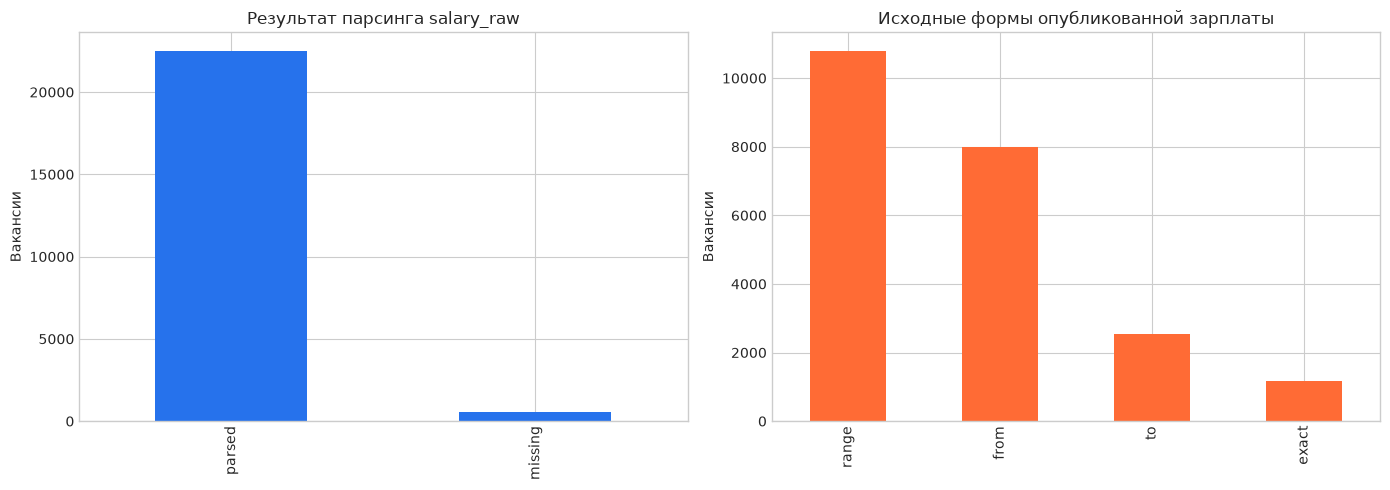

In [3]:
format_stats = (
    df.groupby(["salary_parse_status", "salary_unit", "salary_tax", "salary_shape"], dropna=False)
      .size().rename("n").reset_index().sort_values("n", ascending=False)
)
format_stats["share_all"] = format_stats["n"] / len(df)
display(format_stats.head(30).style.format({"share_all": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["salary_parse_status"].value_counts().plot.bar(ax=axes[0], color="#2672ec")
axes[0].set_title("Результат парсинга salary_raw")
axes[0].set_xlabel("")
axes[0].set_ylabel("Вакансии")

shape_counts = df.loc[df["salary_parse_status"].eq("parsed"), "salary_shape"].value_counts()
shape_counts.plot.bar(ax=axes[1], color="#ff6b35")
axes[1].set_title("Исходные формы опубликованной зарплаты")
axes[1].set_xlabel("")
axes[1].set_ylabel("Вакансии")
plt.tight_layout()
plt.show()

## 2. Нормализация без подмены неизвестных данных

Строгий пересчёт выполняется только при наличии основания:

- месяц: коэффициент 1;
- неделя: `52 / 12`;
- день или смена: только когда из вакансии извлечено число рабочих дней в неделю;
- час: только когда одновременно известны часы в день и дни в неделю;
- `unspecified` и `piecework`: не пересчитываются.

Дополнительно считается **сценарный** ориентир: 176 часов или 21 рабочий день/смена в месяц. Он нужен для анализа чувствительности, но не используется как основной опубликованный таргет.

In [4]:
def first_number(series):
    return pd.to_numeric(
        series.astype("string").str.replace(",", ".", regex=False).str.extract(r"(\d+(?:\.\d+)?)", expand=False),
        errors="coerce",
    )

workdays = first_number(df.get("Количество рабочих дней в неделю", pd.Series(pd.NA, index=df.index)))
hours = first_number(df.get("Количество рабочих часов в день", pd.Series(pd.NA, index=df.index)))
workdays = workdays.where(workdays.between(1, 7))
hours = hours.where(hours.between(1, 24))

strict_factor = pd.Series(np.nan, index=df.index, dtype=float)
strict_factor[df["salary_unit"].eq("month")] = 1.0
strict_factor[df["salary_unit"].eq("week")] = 52 / 12
strict_factor[df["salary_unit"].isin(["day", "shift"]) & workdays.notna()] = workdays * 52 / 12
strict_factor[df["salary_unit"].eq("hour") & workdays.notna() & hours.notna()] = workdays * hours * 52 / 12

scenario_factor = df["salary_unit"].map({"month": 1.0, "week": 52/12, "day": 21.0, "shift": 21.0, "hour": 176.0})
df["monthly_midpoint_strict"] = df["salary_midpoint_rub"] * strict_factor
df["monthly_midpoint_scenario"] = df["salary_midpoint_rub"] * scenario_factor

normalization_coverage = (
    df.loc[df["salary_parse_status"].eq("parsed")]
      .groupby("salary_unit")
      .agg(
          parsed_n=("id", "size"),
          point_n=("salary_midpoint_rub", "count"),
          strict_monthly_n=("monthly_midpoint_strict", "count"),
          scenario_monthly_n=("monthly_midpoint_scenario", "count"),
      )
      .sort_values("parsed_n", ascending=False)
)
normalization_coverage["strict_share_of_points"] = normalization_coverage["strict_monthly_n"] / normalization_coverage["point_n"].replace(0, np.nan)
display(normalization_coverage.style.format({"strict_share_of_points": "{:.1%}"}))

,parsed_n,point_n,strict_monthly_n,scenario_monthly_n,strict_share_of_points
salary_unit,,,,,
unspecified,15798,8842,0,0,0.0%
shift,6304,2874,805,2874,28.0%
piecework,205,134,0,0,0.0%
hour,151,73,35,73,47.9%
week,47,34,34,34,100.0%


## 3. Рейтинг основной когорты

Основной рейтинг строится на закрытых точечных наблюдениях: `exact` и midpoint для `range`. Односторонние границы не отбрасываются из реестра, но не становятся искусственными точками. Единица оплаты и налоговая база входят в ключ сравнения.

Критерии чистого сегмента: не менее 30 наблюдений, 10 работодателей, доля крупнейшего работодателя не выше 30%, относительный IQR не выше 60%, относительная ширина bootstrap-интервала медианы не выше 25%, доля log-MAD-выбросов не выше 10%. Нормальность показана отдельно и не является обязательной для эмпирического Q1–Q3.

In [5]:
base_mask = ~df[["is_vahta", "is_remote", "is_military"]].any(axis=1)
resolved_mask = df["profession_resolved"].notna() & df["city_resolved"].notna()
point_mask = df["salary_shape"].isin(["exact", "range"]) & df["salary_midpoint_rub"].gt(0)
base_points = df.loc[base_mask & resolved_mask & point_mask].copy()

GROUP = ["profession_resolved", "city_resolved", "salary_unit", "salary_tax"]
rng = np.random.default_rng(RANDOM_STATE)

def log_mad_outlier_share(x):
    z = np.log1p(np.asarray(x, dtype=float))
    med = np.median(z)
    mad = np.median(np.abs(z - med))
    if mad == 0:
        return 0.0
    robust_z = 0.6745 * (z - med) / mad
    return float(np.mean(np.abs(robust_z) > 3.5))

def bootstrap_median_ci(x, iterations=300):
    x = np.asarray(x, dtype=float)
    samples = rng.choice(x, size=(iterations, len(x)), replace=True)
    meds = np.median(samples, axis=1)
    return np.quantile(meds, [0.025, 0.975])

def group_stats(g):
    x = g["salary_midpoint_rub"].dropna().to_numpy(float)
    q10, q25, med, q75, q90 = np.quantile(x, [0.10, 0.25, 0.50, 0.75, 0.90])
    lo, hi = bootstrap_median_ci(x)
    employers = g["employer_name_observed"].fillna("Не указан")
    top_share = employers.value_counts(normalize=True).iloc[0]
    normal_p = stats.normaltest(x).pvalue if len(x) >= 20 and np.unique(x).size >= 8 else np.nan
    return pd.Series({
        "n": len(x), "exact_n": g["salary_shape"].eq("exact").sum(), "range_n": g["salary_shape"].eq("range").sum(),
        "employers_n": employers.nunique(), "top_employer_share": top_share,
        "q10": q10, "q25": q25, "median": med, "q75": q75, "q90": q90,
        "iqr_rel": (q75-q25)/med if med else np.nan,
        "skew": stats.skew(x, bias=False) if len(x) > 2 else np.nan,
        "normaltest_p": normal_p,
        "outlier_share": log_mad_outlier_share(x),
        "median_ci_low": lo, "median_ci_high": hi,
        "median_ci_rel_width": (hi-lo)/med if med else np.nan,
    })

eligible_groups = base_points.copy()  # рейтинг охватывает все непустые ячейки, включая класс D
segment_ranking = eligible_groups.groupby(GROUP, dropna=False).apply(group_stats, include_groups=False).reset_index()

# Односторонние границы и пропуски добавляются как контекст сегмента, но не как точки.
all_base = df.loc[base_mask & resolved_mask].copy()
shape_context = (
    all_base.groupby(GROUP + ["salary_shape"], dropna=False).size().unstack(fill_value=0)
    .rename(columns=lambda c: f"shape_{c}").reset_index()
)
segment_ranking = segment_ranking.merge(shape_context, on=GROUP, how="left")

shape_cols = [c for c in ["shape_exact", "shape_range", "shape_from", "shape_to"] if c in segment_ranking]
segment_ranking["parsed_n"] = segment_ranking[shape_cols].sum(axis=1)
segment_ranking["point_share"] = segment_ranking["n"] / segment_ranking["parsed_n"].replace(0, np.nan)

segment_ranking["normal_like"] = segment_ranking["skew"].abs().le(1) & segment_ranking["normaltest_p"].ge(0.01)
segment_ranking["clean_candidate"] = (
    segment_ranking["n"].ge(30)
    & segment_ranking["employers_n"].ge(10)
    & segment_ranking["top_employer_share"].le(0.30)
    & segment_ranking["iqr_rel"].le(0.60)
    & segment_ranking["median_ci_rel_width"].le(0.25)
    & segment_ranking["outlier_share"].le(0.10)
    & segment_ranking["point_share"].ge(0.50)
    & ~segment_ranking["salary_unit"].isin(["unspecified", "piecework"])
)

segment_ranking["stability_score"] = (
    20*np.minimum(segment_ranking["n"]/100, 1)
    + 15*np.minimum(segment_ranking["employers_n"]/30, 1)
    + 20*(1-segment_ranking["top_employer_share"].clip(0, 1))
    + 20*(1-(segment_ranking["iqr_rel"]/1.0).clip(0, 1))
    + 15*(1-(segment_ranking["median_ci_rel_width"]/0.5).clip(0, 1))
    + 10*(1-(segment_ranking["outlier_share"]/0.2).clip(0, 1))
    - 5*segment_ranking["salary_tax"].eq("unknown")
).clip(0, 100).round(1)

segment_ranking["recommendation"] = np.select(
    [
        segment_ranking["clean_candidate"],
        segment_ranking["n"].lt(30),
        segment_ranking["salary_unit"].eq("unspecified"),
        segment_ranking["employers_n"].lt(10) | segment_ranking["top_employer_share"].gt(0.30),
    ],
    ["рекомендуется", "нужен добор", "уточнить период", "проверить концентрацию"],
    default="требует очистки/уточнения",
)
segment_ranking = segment_ranking.sort_values(["clean_candidate", "stability_score", "n"], ascending=[False, False, False])

top_segments = segment_ranking.loc[segment_ranking["clean_candidate"]].head(20)
display(top_segments.style.format({
    "top_employer_share":"{:.1%}", "iqr_rel":"{:.1%}", "outlier_share":"{:.1%}",
    "median_ci_rel_width":"{:.1%}", "normaltest_p":"{:.3f}",
    "q10":"{:,.0f}", "q25":"{:,.0f}", "median":"{:,.0f}", "q75":"{:,.0f}", "q90":"{:,.0f}",
}))

,profession_resolved,city_resolved,salary_unit,salary_tax,n,exact_n,range_n,employers_n,top_employer_share,q10,q25,median,q75,q90,iqr_rel,skew,normaltest_p,outlier_share,median_ci_low,median_ci_high,median_ci_rel_width,shape_exact,shape_from,shape_range,shape_to,shape_unknown,parsed_n,point_share,normal_like,clean_candidate,stability_score,recommendation
482,Курьер,Санкт-Петербург,shift,net,212.000000,0.000000,212.000000,93.000000,10.8%,"4,473","5,250","5,750","7,262","8,755",35.0%,0.808339,0.000,0.5%,5650.000000,6000.000000,6.1%,0,44,212,44,0,300,0.706667,False,True,88.800000,рекомендуется
430,Комплектовщик,Санкт-Петербург,shift,net,98.000000,10.000000,88.000000,55.000000,9.2%,"3,900","4,100","4,638","5,094","6,150",21.4%,9.733620,0.000,4.1%,4343.518750,4750.000000,8.8%,10,66,88,24,0,188,0.521277,False,True,88.800000,рекомендуется
453,Курьер,Екатеринбург,shift,net,143.000000,2.000000,141.000000,108.000000,13.3%,"4,500","5,375","6,398","7,500","9,140",33.2%,0.618784,0.014,0.0%,6000.000000,6500.000000,7.8%,2,41,141,37,0,221,0.647059,True,True,88.400000,рекомендуется
466,Курьер,Москва,shift,net,205.000000,2.000000,203.000000,97.000000,19.5%,"6,100","7,000","8,755","9,200","10,120",25.1%,0.145458,0.034,2.4%,8200.000000,8755.000000,6.3%,2,76,203,29,0,310,0.661290,True,True,88.000000,рекомендуется
527,Продавец,Санкт-Петербург,shift,net,107.000000,25.000000,82.000000,68.000000,9.3%,"3,000","3,688","4,000","5,025","5,500",33.4%,5.421572,0.000,4.7%,3850.000000,4250.000000,10.0%,25,86,82,15,0,208,0.514423,False,True,86.100000,рекомендуется


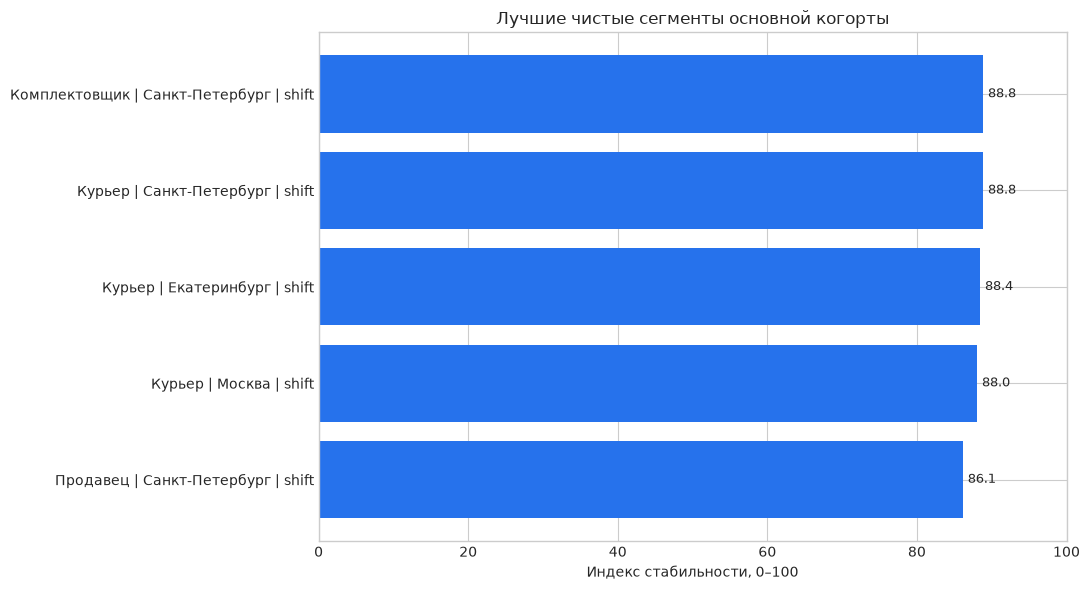

normal_like,False,True
salary_unit,,
hour,22,0
piecework,18,0
shift,152,5
unspecified,319,9
week,16,0


Важно: normaltest чувствителен к размеру выборки. Для разметки 'в рынке' используется эмпирический Q1–Q3; нормальность не требуется.


In [6]:
plot_top = top_segments.head(15).copy().sort_values("stability_score")
plot_top["label"] = plot_top["profession_resolved"] + " | " + plot_top["city_resolved"] + " | " + plot_top["salary_unit"]

fig, ax = plt.subplots(figsize=(11, max(6, len(plot_top)*0.45)))
ax.barh(plot_top["label"], plot_top["stability_score"], color="#2672ec")
ax.set_xlim(0, 100)
ax.set_xlabel("Индекс стабильности, 0–100")
ax.set_title("Лучшие чистые сегменты основной когорты")
for y, score in enumerate(plot_top["stability_score"]):
    ax.text(score+0.7, y, f"{score:.1f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

normal_summary = segment_ranking.groupby(["salary_unit", "normal_like"]).size().unstack(fill_value=0)
display(normal_summary)
print("Важно: normaltest чувствителен к размеру выборки. Для разметки 'в рынке' используется эмпирический Q1–Q3; нормальность не требуется.")

## 4. Вахта и удалённая работа как отдельные треки

Эти вакансии не входят в основной рейтинг. Для каждой когорты строится собственный рейтинг по тем же правилам. Вахтовая зарплата требует длительности вахты и периода отдыха; удалённая работа требует отдельной проверки роли географии. Если `city_resolved` отсутствует, вакансия не подменяется искусственным городом.

,cohort,n,resolved_profession_city_share,parsed_salary_share,point_salary_share,unspecified_unit_share_among_parsed,vahta_duration_filled_share
0,вахта,4600,48.8%,99.3%,50.7%,75.8%,0.680870
1,удалённая работа,2936,5.0%,90.0%,55.0%,85.8%,0.000000


Форматы вахты:


,salary_unit,salary_shape,n
9,unspecified,range,1624
8,unspecified,from,1396
5,shift,range,475
4,shift,from,431
10,unspecified,to,309
7,unspecified,exact,131
6,shift,to,98
3,shift,exact,96
2,piecework,range,5
0,hour,exact,1


Форматы удалённой работы:


,salary_unit,salary_shape,n
14,unspecified,range,1311
13,unspecified,from,761
10,shift,range,129
15,unspecified,to,126
12,unspecified,exact,68
6,piecework,range,66
9,shift,from,39
5,piecework,from,38
1,hour,from,26
11,shift,to,23


Рейтинг вахтовых сегментов:


... (3 outputs left out)

Длительность вахты:


,Длительность вахты,n
0,Не указана,1468
1,60,333
2,30,194
3,90,166
4,15,152
5,"30, 45, 60, 90",138
6,"60, 90",124
7,"30, 60, 90",109
8,"30, 45, 60",102
9,"25, 35, 45, 60, 90",79


География удалённых вакансий:


,city_resolved,n
0,Москва,973
1,Санкт-Петербург,174
2,Не определён,106
3,Краснодар,90
4,Ростов-на-Дону,69
5,Екатеринбург,65
6,Новосибирск,65
7,Казань,53
8,Воронеж,41
9,Нижний Новгород,36


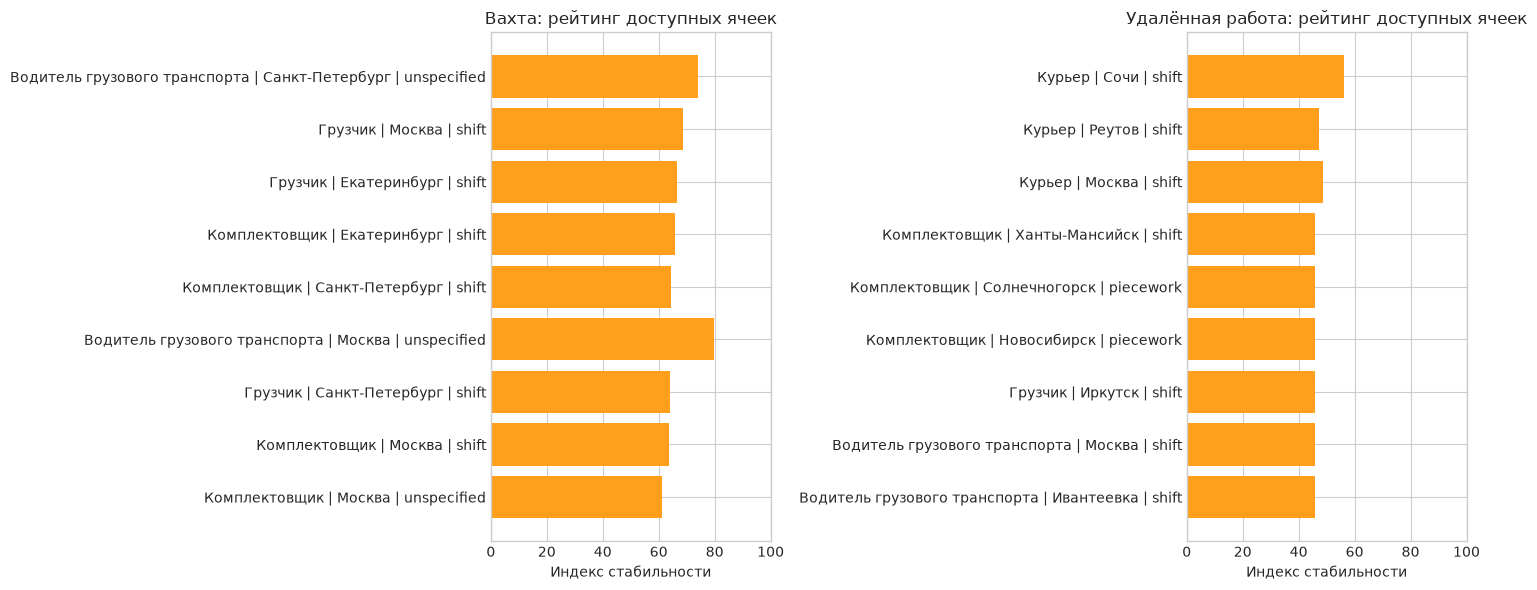

In [7]:
def special_cohort_summary(mask, name):
    part = df.loc[mask & ~df["is_military"]].copy()
    resolved = part["profession_resolved"].notna() & part["city_resolved"].notna()
    parsed = part["salary_parse_status"].eq("parsed")
    point = part["salary_shape"].isin(["exact", "range"]) & part["salary_midpoint_rub"].gt(0)
    summary = pd.DataFrame({
        "cohort": [name], "n": [len(part)],
        "resolved_profession_city_share": [resolved.mean()],
        "parsed_salary_share": [parsed.mean()],
        "point_salary_share": [point.mean()],
        "unspecified_unit_share_among_parsed": [part.loc[parsed, "salary_unit"].eq("unspecified").mean() if parsed.any() else np.nan],
        "vahta_duration_filled_share": [part.get("Длительность вахты", pd.Series(pd.NA, index=part.index)).notna().mean()],
    })
    formats = part.loc[parsed].groupby(["salary_unit", "salary_shape"]).size().rename("n").reset_index()
    return summary, formats

def add_rating_and_needs(ranking):
    ranking = ranking.copy()
    shape_cols = [c for c in ["shape_exact", "shape_range", "shape_from", "shape_to"] if c in ranking]
    ranking["parsed_n"] = ranking[shape_cols].sum(axis=1) if shape_cols else ranking["n"]
    ranking["point_share"] = ranking["n"] / ranking["parsed_n"].replace(0, np.nan)
    ranking["normal_like"] = ranking["skew"].abs().le(1) & ranking["normaltest_p"].ge(0.01)
    ranking["clean_candidate"] = (
        ranking["n"].ge(30)
        & ranking["employers_n"].ge(10)
        & ranking["top_employer_share"].le(0.30)
        & ranking["iqr_rel"].le(0.60)
        & ranking["median_ci_rel_width"].le(0.25)
        & ranking["outlier_share"].le(0.10)
        & ranking["point_share"].ge(0.50)
        & ~ranking["salary_unit"].isin(["unspecified", "piecework"])
    )
    ranking["stability_score"] = (
        20*np.minimum(ranking["n"]/100, 1)
        + 15*np.minimum(ranking["employers_n"]/30, 1)
        + 20*(1-ranking["top_employer_share"].clip(0, 1))
        + 20*(1-(ranking["iqr_rel"]/1.0).clip(0, 1))
        + 15*(1-(ranking["median_ci_rel_width"]/0.5).clip(0, 1))
        + 10*(1-(ranking["outlier_share"]/0.2).clip(0, 1))
        - 5*ranking["salary_tax"].eq("unknown")
        - 10*ranking["salary_unit"].eq("unspecified")
    ).clip(0, 100).round(1)

    def classify(r):
        if r["clean_candidate"]:
            return "A — рекомендуется"
        if r["n"] < 5:
            return "D — пока непригоден"
        if r["n"] < 30:
            return "C — нужен добор"
        if r["salary_unit"] in {"unspecified", "piecework"} or r["point_share"] < .50:
            return "B — нужно уточнение формата"
        return "B — нужна очистка/проверка"

    def need(r):
        needs = []
        if r["n"] < 50:
            needs.append(f"добрать минимум {int(50-r['n'])} сопоставимых вакансий")
        if r["employers_n"] < 10:
            needs.append(f"расширить до 10 работодателей (сейчас {int(r['employers_n'])})")
        if r["top_employer_share"] > .30:
            needs.append("снизить концентрацию крупнейшего работодателя до 30%")
        if r["salary_unit"] == "unspecified":
            needs.append("извлечь или подтвердить период оплаты")
        if r["salary_unit"] == "piecework":
            needs.append("добавить единицу объёма сдельной работы")
        if r["point_share"] < .50:
            needs.append("добрать закрытые вилки/точные суммы; границы from/to преобладают")
        if r["iqr_rel"] > .60:
            needs.append("разделить неоднородный сегмент по условиям работы")
        if r["median_ci_rel_width"] > .25:
            needs.append("увеличить выборку для устойчивой медианы")
        if r["outlier_share"] > .10:
            needs.append("проверить аномальные зарплаты и единицы оплаты")
        return "; ".join(needs) if needs else "добор не требуется"

    ranking["eligibility_class"] = ranking.apply(classify, axis=1)
    ranking["collection_need"] = ranking.apply(need, axis=1)
    return ranking.sort_values(["clean_candidate", "stability_score", "n"], ascending=[False, False, False])

def cohort_ranking(mask, cohort_name, min_points=1):
    resolved = df["profession_resolved"].notna() & df["city_resolved"].notna()
    points = df.loc[
        mask & ~df["is_military"] & resolved
        & df["salary_shape"].isin(["exact", "range"])
        & df["salary_midpoint_rub"].gt(0)
    ].copy()
    if points.empty:
        return pd.DataFrame()
    retained = points.groupby(GROUP, dropna=False).filter(lambda g: len(g) >= min_points)
    if retained.empty:
        return pd.DataFrame()
    ranking = retained.groupby(GROUP, dropna=False).apply(group_stats, include_groups=False).reset_index()
    context = (
        df.loc[mask & ~df["is_military"] & resolved]
          .groupby(GROUP + ["salary_shape"], dropna=False).size().unstack(fill_value=0)
          .rename(columns=lambda c: f"shape_{c}").reset_index()
    )
    ranking = ranking.merge(context, on=GROUP, how="left")
    ranking.insert(0, "cohort", cohort_name)
    return add_rating_and_needs(ranking)

vahta_summary, vahta_formats = special_cohort_summary(df["is_vahta"], "вахта")
remote_summary, remote_formats = special_cohort_summary(df["is_remote"], "удалённая работа")
special_summary = pd.concat([vahta_summary, remote_summary], ignore_index=True)
display(special_summary.style.format({
    "resolved_profession_city_share":"{:.1%}", "parsed_salary_share":"{:.1%}",
    "point_salary_share":"{:.1%}", "unspecified_unit_share_among_parsed":"{:.1%}",
}))
print("Форматы вахты:")
display(vahta_formats.sort_values("n", ascending=False))
print("Форматы удалённой работы:")
display(remote_formats.sort_values("n", ascending=False))

vahta_ranking = cohort_ranking(df["is_vahta"], "вахта")
remote_ranking = cohort_ranking(df["is_remote"], "удалённая работа")

print("Рейтинг вахтовых сегментов:")
display(vahta_ranking.head(20))
print("Рейтинг удалённых сегментов:")
display(remote_ranking.head(20))

vahta_duration_counts = (
    df.loc[df["is_vahta"] & ~df["is_military"], "Длительность вахты"]
      .fillna("Не указана").astype(str).value_counts().rename_axis("Длительность вахты").reset_index(name="n")
)
remote_city_counts = (
    df.loc[df["is_remote"] & ~df["is_military"], "city_resolved"]
      .fillna("Не определён").astype(str).value_counts().rename_axis("city_resolved").reset_index(name="n")
)
print("Длительность вахты:")
display(vahta_duration_counts.head(20))
print("География удалённых вакансий:")
display(remote_city_counts.head(20))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, ranking, title in [
    (axes[0], vahta_ranking, "Вахта"),
    (axes[1], remote_ranking, "Удалённая работа"),
]:
    top = ranking.head(10).sort_values("stability_score") if not ranking.empty else ranking
    if top.empty:
        ax.text(.5, .5, "Нет сегментов с ≥5 точками", ha="center", va="center")
        ax.set_axis_off()
        continue
    labels = top["profession_resolved"] + " | " + top["city_resolved"] + " | " + top["salary_unit"]
    colors = np.where(top["clean_candidate"], "#2ca02c", "#ff9f1c")
    ax.barh(labels, top["stability_score"], color=colors)
    ax.set_xlim(0, 100)
    ax.set_title(f"{title}: рейтинг доступных ячеек")
    ax.set_xlabel("Индекс стабильности")
plt.tight_layout(); plt.show()

## 5. Добор данных и параметризованный профиль

Добор формируется для групп, где уже есть хотя бы 10 сопоставимых наблюдений, но не достигнут порог 50. Профиль ниже принимает профессию, город, единицу оплаты и налоговую базу без переписывания расчётов.

,cohort,profession_resolved,city_resolved,salary_unit,salary_tax,n,parsed_n,point_share,employers_n,top_employer_share,stability_score,eligibility_class,collection_need,needed_to_50
541,вахта,Водитель грузового транспорта,Москва,unspecified,net,175.0,320,0.546875,161.0,0.022857,79.9,B — нужно уточнение формата,извлечь или подтвердить период оплаты,0
542,вахта,Водитель грузового транспорта,Санкт-Петербург,unspecified,net,69.0,135,0.511111,64.0,0.043478,74.0,B — нужно уточнение формата,извлечь или подтвердить период оплаты,0
543,вахта,Грузчик,Москва,shift,net,21.0,42,0.500000,21.0,0.047619,68.7,C — нужен добор,добрать минимум 29 сопоставимых вакансий,29
544,вахта,Грузчик,Екатеринбург,shift,net,25.0,47,0.531915,24.0,0.080000,66.5,C — нужен добор,добрать минимум 25 сопоставимых вакансий; пров...,25
545,вахта,Комплектовщик,Екатеринбург,shift,net,21.0,46,0.456522,21.0,0.047619,65.8,C — нужен добор,добрать минимум 29 сопоставимых вакансий; добр...,29
546,вахта,Водитель грузового транспорта,Москва,unspecified,unknown,74.0,113,0.654867,70.0,0.040541,64.4,B — нужно уточнение формата,извлечь или подтвердить период оплаты,0
547,вахта,Комплектовщик,Санкт-Петербург,shift,net,27.0,54,0.500000,21.0,0.148148,64.4,C — нужен добор,добрать минимум 23 сопоставимых вакансий; увел...,23
548,вахта,Грузчик,Санкт-Петербург,shift,net,14.0,35,0.400000,14.0,0.071429,63.9,C — нужен добор,добрать минимум 36 сопоставимых вакансий; добр...,36
549,вахта,Комплектовщик,Москва,shift,net,26.0,65,0.400000,25.0,0.076923,63.5,C — нужен добор,добрать минимум 24 сопоставимых вакансий; добр...,24
550,вахта,Комплектовщик,Москва,unspecified,net,60.0,106,0.566038,45.0,0.083333,61.3,B — нужно уточнение формата,извлечь или подтвердить период оплаты; раздели...,0


,salary_unit,salary_tax,n,q10,q25,median,q75,q90
0,shift,net,212,"4,473","5,250","5,750","7,262","8,755"


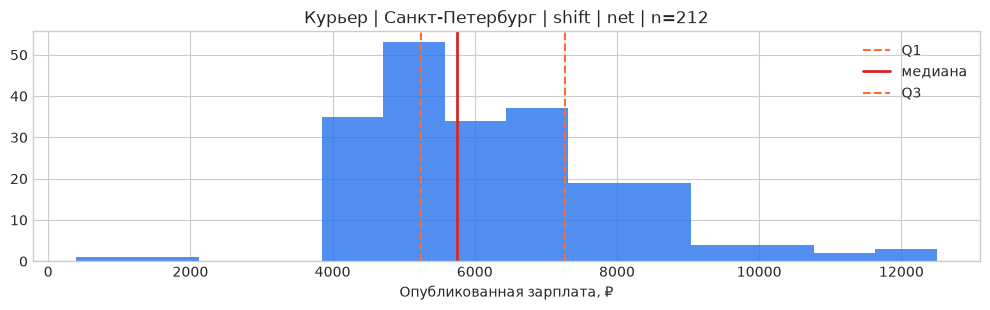

In [8]:
# Единый рейтинг всех трёх когорт и явные потребности в доборе.
base_full = add_rating_and_needs(segment_ranking).copy()
base_full.insert(0, "cohort", "основная")
all_cohort_ranking = pd.concat([base_full, vahta_ranking, remote_ranking], ignore_index=True, sort=False)
all_cohort_ranking = all_cohort_ranking.sort_values(["cohort", "clean_candidate", "stability_score"], ascending=[True, False, False])

data_needs = all_cohort_ranking.loc[
    ~all_cohort_ranking["clean_candidate"],
    ["cohort"] + GROUP + ["n", "parsed_n", "point_share", "employers_n", "top_employer_share", "stability_score", "eligibility_class", "collection_need"],
].copy()
data_needs["needed_to_50"] = (50 - data_needs["n"]).clip(lower=0).astype(int)
data_needs = data_needs.sort_values(["cohort", "stability_score", "n"], ascending=[True, False, False])
display(data_needs.head(30))

def salary_profile(profession, city, unit=None, tax=None, show_plot=True):
    mask = (
        base_mask
        & df["profession_resolved"].eq(profession)
        & df["city_resolved"].eq(city)
        & df["salary_shape"].isin(["exact", "range"])
        & df["salary_midpoint_rub"].gt(0)
    )
    if unit is not None:
        mask &= df["salary_unit"].eq(unit)
    if tax is not None:
        mask &= df["salary_tax"].eq(tax)
    part = df.loc[mask].copy()
    if part.empty:
        print("Сопоставимых наблюдений нет")
        return pd.DataFrame()
    result = (
        part.groupby(["salary_unit", "salary_tax"])["salary_midpoint_rub"]
        .agg(n="size", q10=lambda x:x.quantile(.10), q25=lambda x:x.quantile(.25), median="median", q75=lambda x:x.quantile(.75), q90=lambda x:x.quantile(.90))
        .reset_index()
    )
    display(result.style.format({c:"{:,.0f}" for c in ["q10","q25","median","q75","q90"]}))
    if show_plot:
        groups = list(part.groupby(["salary_unit", "salary_tax"], dropna=False))
        fig, axes = plt.subplots(len(groups), 1, figsize=(10, 3.2*len(groups)), squeeze=False)
        for ax, ((u,t), g) in zip(axes.ravel(), groups):
            x = g["salary_midpoint_rub"]
            ax.hist(x, bins=min(30, max(8, int(np.sqrt(len(x))))), color="#2672ec", alpha=.8)
            ax.axvline(x.quantile(.25), color="#ff6b35", ls="--", label="Q1")
            ax.axvline(x.median(), color="#d62728", lw=2, label="медиана")
            ax.axvline(x.quantile(.75), color="#ff6b35", ls="--", label="Q3")
            ax.set_title(f"{profession} | {city} | {u} | {t} | n={len(x)}")
            ax.set_xlabel("Опубликованная зарплата, ₽")
            ax.legend()
        plt.tight_layout(); plt.show()
    return result

if not top_segments.empty:
    example = top_segments.iloc[0]
    salary_profile(example["profession_resolved"], example["city_resolved"], example["salary_unit"], example["salary_tax"])

In [9]:
# Экспорт расчётов для аналитики и ML.
format_stats.to_csv(OUTPUT_DIR / "salary_format_stats.csv", index=False)
normalization_coverage.reset_index().to_csv(OUTPUT_DIR / "normalization_coverage.csv", index=False)
segment_ranking.to_csv(OUTPUT_DIR / "segment_salary_ranking.csv", index=False)
top_segments.to_csv(OUTPUT_DIR / "recommended_segments.csv", index=False)
all_cohort_ranking.to_csv(OUTPUT_DIR / "all_cohorts_segment_ranking.csv", index=False)
vahta_ranking.to_csv(OUTPUT_DIR / "vahta_segment_ranking.csv", index=False)
remote_ranking.to_csv(OUTPUT_DIR / "remote_segment_ranking.csv", index=False)
data_needs.to_csv(OUTPUT_DIR / "segments_for_additional_collection.csv", index=False)
special_summary.to_csv(OUTPUT_DIR / "vahta_remote_summary.csv", index=False)
vahta_formats.to_csv(OUTPUT_DIR / "vahta_formats.csv", index=False)
remote_formats.to_csv(OUTPUT_DIR / "remote_formats.csv", index=False)
vahta_duration_counts.to_csv(OUTPUT_DIR / "vahta_duration_counts.csv", index=False)
remote_city_counts.to_csv(OUTPUT_DIR / "remote_city_counts.csv", index=False)

import json
ml_contract = {
    "segment_key": ["profession_resolved", "city_resolved", "salary_unit", "salary_tax"],
    "target": "salary_midpoint_rub only for salary_shape in {exact, range}",
    "in_market_rule": "q25 <= salary_midpoint_rub <= q75 within the same segment key",
    "excluded_from_point_target": ["from", "to", "unknown", "missing"],
    "separate_cohorts": ["основная", "вахта", "удалённая работа"],
    "military": "excluded",
    "normality_required": False,
    "strict_normalization": {
        "month": 1,
        "week": "52/12",
        "day_or_shift": "workdays_per_week * 52/12, only when workdays are observed",
        "hour": "hours_per_day * workdays_per_week * 52/12, only when both are observed",
        "unspecified_or_piecework": None,
    },
}
(OUTPUT_DIR / "ml_salary_contract.json").write_text(json.dumps(ml_contract, ensure_ascii=False, indent=2), encoding="utf-8")

top_lines = []
for _, r in top_segments.head(10).iterrows():
    top_lines.append(
        f"- {r['profession_resolved']} | {r['city_resolved']} | {r['salary_unit']} | {r['salary_tax']}: "
        f"n={int(r['n'])}, медиана={r['median']:,.0f} ₽, Q1–Q3={r['q25']:,.0f}–{r['q75']:,.0f} ₽, score={r['stability_score']:.1f}"
    )

def cohort_result_line(name, ranking, summary):
    recommended = ranking.loc[ranking["clean_candidate"]] if not ranking.empty else ranking
    city_share = float(summary["resolved_profession_city_share"].iloc[0])
    unit_unknown = float(summary["unspecified_unit_share_among_parsed"].iloc[0])
    if recommended.empty:
        return (
            f"- **{name}: строгих кандидатов нет.** Заполненность пары профессия–город {city_share:.1%}; "
            f"доля неизвестного периода среди распознанных зарплат {unit_unknown:.1%}. "
            "Нужны точные/закрытые зарплаты с явным периодом и заполненные ключи сегмента."
        )
    leaders = ", ".join(
        f"{r.profession_resolved} / {r.city_resolved} / {r.salary_unit} (n={int(r.n)})"
        for r in recommended.head(3).itertuples()
    )
    return (
        f"- **{name}: {len(recommended)} строгих кандидатов.** Лидеры: {leaders}. "
        f"Заполненность пары профессия–город {city_share:.1%}; неизвестный период {unit_unknown:.1%}."
    )

vahta_line = cohort_result_line("Вахта", vahta_ranking, vahta_summary)
remote_line = cohort_result_line("Удалённая работа", remote_ranking, remote_summary)

def near_candidate_lines(ranking, limit=3):
    if ranking.empty:
        return "- Нет ячеек для ранжирования."
    rows = []
    for r in ranking.head(limit).itertuples():
        rows.append(
            f"- {r.profession_resolved} | {r.city_resolved} | {r.salary_unit} | {r.salary_tax}: "
            f"n={int(r.n)}, score={r.stability_score:.1f}; {r.collection_need}."
        )
    return "\n".join(rows)

vahta_near = near_candidate_lines(vahta_ranking)
remote_near = near_candidate_lines(remote_ranking)

summary_text = f'''# Итоги зарплатного исследования

Датасет: {len(df):,} уникальных вакансий, SHA-256 `{dataset_hash}`.

Основной рейтинг исключает вахту, удалённую работу и military. В расчёт рейтинга входят только разрешённые ячейки `profession_resolved × city_resolved`, отдельно по единице оплаты и налоговой базе. Exact и midpoint закрытой вилки используются как точечный аналитический показатель; `from/to` не превращаются в точки.

## Рекомендуемые сегменты
{chr(10).join(top_lines) if top_lines else '- Сегменты, прошедшие строгие пороги, не найдены.'}

## Отдельные результаты
{vahta_line}
{remote_line}

### Вахта: ближайшие к пригодности ячейки
{vahta_near}

Для вахты первичная проблема не в общем объёме: у крупных ячеек водителей достаточно наблюдений, но в 75.8% распознанных зарплат период не указан. До подтверждения «за месяц / за вахту / за смену» эти суммы нельзя объединять. Для сменных сегментов нужен адресный добор закрытых вилок и точных сумм.

### Удалённая работа: ближайшие к пригодности ячейки
{remote_near}

Для удалёнки разрез `город × профессия` заполнен только у 5.0% вакансий. Массовый добор по тем же фильтрам не решит проблему, если город продолжит отсутствовать. Сначала нужно либо восстановить географию, либо согласовать отдельный национальный сегмент `профессия × удалённая работа`; текущий обязательный городской ключ не позволяет рекомендовать удалённые сегменты.

## Критерии пригодности
- **A — рекомендуется:** n≥30, ≥10 работодателей, крупнейший работодатель ≤30%, IQR/медиана ≤60%, относительная ширина bootstrap CI медианы ≤25%, выбросы ≤10%, не менее половины зарплат представлены точкой или закрытой вилкой, период оплаты известен.
- **B — преобразование/проверка:** объём достаточен, но неизвестен период, преобладают границы `from/to`, есть концентрация или неоднородность.
- **C — нужен добор:** менее 30 сопоставимых наблюдений; целевой ориентир таблицы добора — 50.
- **D — пока непригоден:** меньше 5 сопоставимых точек либо ключ сегмента почти не заполнен.

Таблица `segments_for_additional_collection.csv` содержит не только число вакансий для добора, но и причину: период, работодатели, закрытые вилки, неоднородность или выбросы.

## Методические выводы
- Q1–Q3 можно использовать как эмпирический ориентир «в рынке» без требования нормальности.
- `unspecified` нельзя считать месяцем без подтверждения периода.
- Сдельная оплата несопоставима без объёма работы.
- Строгая нормализация смены/дня/часа возможна только при заполненной нагрузке; сценарные 21 день и 176 часов не должны становиться основным таргетом.
- Вахта требует длительности вахты и периода отдыха. Удалёнка требует отдельной проверки роли географии.
- Односторонние границы должны использоваться в моделях цензурированных данных либо как отдельный формат, но не как точная зарплата.
'''
(OUTPUT_DIR / "SUMMARY.md").write_text(summary_text, encoding="utf-8")

print(f"Сохранено файлов: {len(list(OUTPUT_DIR.iterdir()))}")
display(Markdown(summary_text))

Сохранено файлов: 15


# Итоги зарплатного исследования

Датасет: 23,036 уникальных вакансий, SHA-256 `835f5ac1c0ba1770d7fdd0718261f3445bff11acec653c795daa3c250d4e29d7`.

Основной рейтинг исключает вахту, удалённую работу и military. В расчёт рейтинга входят только разрешённые ячейки `profession_resolved × city_resolved`, отдельно по единице оплаты и налоговой базе. Exact и midpoint закрытой вилки используются как точечный аналитический показатель; `from/to` не превращаются в точки.

## Рекомендуемые сегменты
- Курьер | Санкт-Петербург | shift | net: n=212, медиана=5,750 ₽, Q1–Q3=5,250–7,262 ₽, score=88.8
- Комплектовщик | Санкт-Петербург | shift | net: n=98, медиана=4,638 ₽, Q1–Q3=4,100–5,094 ₽, score=88.8
- Курьер | Екатеринбург | shift | net: n=143, медиана=6,398 ₽, Q1–Q3=5,375–7,500 ₽, score=88.4
- Курьер | Москва | shift | net: n=205, медиана=8,755 ₽, Q1–Q3=7,000–9,200 ₽, score=88.0
- Продавец | Санкт-Петербург | shift | net: n=107, медиана=4,000 ₽, Q1–Q3=3,688–5,025 ₽, score=86.1

## Отдельные результаты
- **Вахта: строгих кандидатов нет.** Заполненность пары профессия–город 48.8%; доля неизвестного периода среди распознанных зарплат 75.8%. Нужны точные/закрытые зарплаты с явным периодом и заполненные ключи сегмента.
- **Удалённая работа: строгих кандидатов нет.** Заполненность пары профессия–город 5.0%; доля неизвестного периода среди распознанных зарплат 85.8%. Нужны точные/закрытые зарплаты с явным периодом и заполненные ключи сегмента.

### Вахта: ближайшие к пригодности ячейки
- Водитель грузового транспорта | Москва | unspecified | net: n=175, score=79.9; извлечь или подтвердить период оплаты.
- Водитель грузового транспорта | Санкт-Петербург | unspecified | net: n=69, score=74.0; извлечь или подтвердить период оплаты.
- Грузчик | Москва | shift | net: n=21, score=68.7; добрать минимум 29 сопоставимых вакансий.

Для вахты первичная проблема не в общем объёме: у крупных ячеек водителей достаточно наблюдений, но в 75.8% распознанных зарплат период не указан. До подтверждения «за месяц / за вахту / за смену» эти суммы нельзя объединять. Для сменных сегментов нужен адресный добор закрытых вилок и точных сумм.

### Удалённая работа: ближайшие к пригодности ячейки
- Курьер | Сочи | shift | net: n=2, score=56.1; добрать минимум 48 сопоставимых вакансий; расширить до 10 работодателей (сейчас 2); снизить концентрацию крупнейшего работодателя до 30%.
- Курьер | Москва | shift | net: n=8, score=48.8; добрать минимум 42 сопоставимых вакансий; расширить до 10 работодателей (сейчас 3); снизить концентрацию крупнейшего работодателя до 30%.
- Курьер | Реутов | shift | unknown: n=2, score=47.4; добрать минимум 48 сопоставимых вакансий; расширить до 10 работодателей (сейчас 2); снизить концентрацию крупнейшего работодателя до 30%.

Для удалёнки разрез `город × профессия` заполнен только у 5.0% вакансий. Массовый добор по тем же фильтрам не решит проблему, если город продолжит отсутствовать. Сначала нужно либо восстановить географию, либо согласовать отдельный национальный сегмент `профессия × удалённая работа`; текущий обязательный городской ключ не позволяет рекомендовать удалённые сегменты.

## Критерии пригодности
- **A — рекомендуется:** n≥30, ≥10 работодателей, крупнейший работодатель ≤30%, IQR/медиана ≤60%, относительная ширина bootstrap CI медианы ≤25%, выбросы ≤10%, не менее половины зарплат представлены точкой или закрытой вилкой, период оплаты известен.
- **B — преобразование/проверка:** объём достаточен, но неизвестен период, преобладают границы `from/to`, есть концентрация или неоднородность.
- **C — нужен добор:** менее 30 сопоставимых наблюдений; целевой ориентир таблицы добора — 50.
- **D — пока непригоден:** меньше 5 сопоставимых точек либо ключ сегмента почти не заполнен.

Таблица `segments_for_additional_collection.csv` содержит не только число вакансий для добора, но и причину: период, работодатели, закрытые вилки, неоднородность или выбросы.

## Методические выводы
- Q1–Q3 можно использовать как эмпирический ориентир «в рынке» без требования нормальности.
- `unspecified` нельзя считать месяцем без подтверждения периода.
- Сдельная оплата несопоставима без объёма работы.
- Строгая нормализация смены/дня/часа возможна только при заполненной нагрузке; сценарные 21 день и 176 часов не должны становиться основным таргетом.
- Вахта требует длительности вахты и периода отдыха. Удалёнка требует отдельной проверки роли географии.
- Односторонние границы должны использоваться в моделях цензурированных данных либо как отдельный формат, но не как точная зарплата.


## 6. Проверка нормальности при α = 0,05

Критерий Лиллиефорса (ЭФР, модификация критерия Колмогорова–Смирнова) сравнивает
эмпирическую функцию распределения с нормальной. Среднее и стандартное отклонение
неизвестны и оцениваются по той же выборке, поэтому используем калибровку Лиллиефорса
в `statsmodels` (`pvalmethod="table"`). Статистика D — максимальное расстояние между
двумя функциями распределения. H₀ предполагает независимые наблюдения из непрерывного
нормального распределения с неизвестными средним и дисперсией.
Отклоняем H₀ при p ≤ 0,05. Неотклонение H₀ оставляет форму неопределённой.
Таблица `statsmodels` ограничивает p снизу 0,001 и сверху 0,990.
Поправка Холма контролирует вероятность хотя бы одного ложного отклонения в явно
указанном семействе при валидных p-значениях. В таблицах сохраняются исходные и
скорректированные p. Порог n ≥ 20 взят из исходной зарплатной диагностики, константы
пропускаются. Для допуска зарплатного разреза применяется отдельный исходный порог n ≥ 30.

[Документация statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html) ·
[Ограничения критерия Колмогорова–Смирнова, NIST](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35g.htm)

Единица анализа — объявление; из зарплат берём положительные точные суммы и
середины закрытых вилок сразу после исходного парсинга. Ключ группы —
когорта × профессия × город × период × налоговая база. Границы «от/до» участвуют
в подсчёте охвата. Сдельную оплату и разрезы с неизвестным периодом или
налоговой базой показываем с причиной пропуска. Группы из зарплатного рейтинга
проверяем отдельно по когортам. У вахты и удалёнки сохраняем исходные маски,
которые могут пересекаться.

Основной тест проводится на принятой для ML точечной цели. В проверках
чувствительности анализируем точные суммы и середины вилок по отдельности,
а также берём по одной случайной вакансии у каждого указанного работодателя
внутри разреза (seed = 42). Последняя проверка меняет вес работодателей, удаляет
анонимные записи и не устраняет все зависимости между вакансиями. Поправку Холма
считаем отдельно по всем выполненным тестам для каждого из этих четырёх вариантов.

Форма относится к опубликованным значениям на снимке. Повторяющиеся суммы,
округление, середины вилок и публикации одной сети могут влиять на p.
Распределение фактически выплаченных зарплат требует других данных. Для ответа
«можно ли использовать сегмент» проверяем исходные критерии пригодности,
включая размер, долю точек, налоговую базу и концентрацию. Q1–Q3 рассчитывается
эмпирически в пределах одного сопоставимого разреза.

[Решение по пулу от 9 ноября](https://buildin.ai/edd3c58d-862e-4307-a71f-9b9182d78baa) ·
[Паспорта](salary_segment_results/priority_segment_passports.md)

In [10]:

KNOWN_UNITS = {"month", "shift", "day", "week", "hour"}
TESTS = ("Точечная цель", "Точные суммы", "Середины вилок", "Одна вакансия на работодателя")
KNOWN_TAX = {"gross", "net"}
cohort_frames = {
    "основная": df.loc[base_mask & resolved_mask],
    "вахта": df.loc[df["is_vahta"] & ~df["is_military"] & resolved_mask],
    "удалённая работа": df.loc[df["is_remote"] & ~df["is_military"] & resolved_mask],
}

rows = []
for cohort, part in cohort_frames.items():
    for keys, group in part.groupby(GROUP):
        profession, city, unit, tax = keys
        if not group["salary_parse_status"].eq("parsed").any():
            continue
        points = group.loc[point_mask.reindex(group.index)]
        names = points["employer_name_observed"].astype("string").str.casefold().str.strip()
        known = names.notna() & ~names.isin(["", "пользователь", "частное лицо", "не указан", "нет данных"])
        employers = points.loc[known].assign(employer=names.loc[known])
        one_per_employer = employers.sample(frac=1, random_state=42).drop_duplicates("employer")
        skip_reason = None
        if unit not in KNOWN_UNITS:
            skip_reason = "Не указан период или единица сдельной оплаты"
        elif tax not in KNOWN_TAX:
            skip_reason = "Не указана налоговая база"
        for variant, sample in zip(TESTS, [
            points, points.loc[points["salary_shape"].eq("exact")],
            points.loc[points["salary_shape"].eq("range")], one_per_employer,
        ]):
            values = sample["salary_midpoint_rub"]
            q1, median, q3 = values.quantile([.25, .5, .75])
            rows.append(dict(
                cohort=cohort, **dict(zip(GROUP, keys)), variant=variant,
                parsed_n=int(group["salary_parse_status"].eq("parsed").sum()),
                one_sided=int(group["salary_shape"].isin(["from", "to"]).sum()),
                employers_known=names.loc[known].nunique(),
                top_value_share=values.value_counts(normalize=True).max(),
                q1=q1, median=median, q3=q3, **lilliefors_row(values, skip_reason),
            ))

salary_tests = pd.concat(
    [holm(group) for _, group in pd.DataFrame(rows).groupby("variant", sort=False)],
    ignore_index=True,
)
primary = salary_tests.loc[salary_tests["variant"].eq(TESTS[0])].copy()
test_cols = GROUP + ["n", "unique", "top_value_share", "D", "p", "p_Holm", "status_Holm"]
display(primary.groupby(["cohort", "status"]).size().unstack(fill_value=0))
display(salary_tests.loc[salary_tests["p"].notna()].groupby(
    ["variant", "status", "status_Holm"]).size().rename("tests").reset_index())
display(primary.loc[primary["p"].notna(), ["cohort", *test_cols]])


status,H₀ не отвергнута,H₀ отвергнута,n < 20,"Константа, тест неприменим",Не указан период или единица сдельной оплаты,Не указана налоговая база,Нет точечных наблюдений
cohort,,,,,,,
вахта,1,5,13,46,262,51,40
основная,1,16,37,96,541,70,136
удалённая работа,0,0,2,11,43,13,9


,variant,status,status_Holm,tests
0,Одна вакансия на работодателя,H₀ не отвергнута,H₀ не отвергнута,6
1,Одна вакансия на работодателя,H₀ отвергнута,H₀ не отвергнута,4
2,Одна вакансия на работодателя,H₀ отвергнута,H₀ отвергнута,11
3,Середины вилок,H₀ не отвергнута,H₀ не отвергнута,3
4,Середины вилок,H₀ отвергнута,H₀ не отвергнута,4
5,Середины вилок,H₀ отвергнута,H₀ отвергнута,13
6,Точечная цель,H₀ не отвергнута,H₀ не отвергнута,2
7,Точечная цель,H₀ отвергнута,H₀ не отвергнута,4
8,Точечная цель,H₀ отвергнута,H₀ отвергнута,17
9,Точные суммы,H₀ не отвергнута,H₀ не отвергнута,1


,cohort,profession_resolved,city_resolved,salary_unit,salary_tax,n,unique,top_value_share,D,p,p_Holm,status_Holm
18,основная,Водитель грузового транспорта,Москва,shift,net,24,16,0.291667,0.196545,0.018687,0.099625,H₀ не отвергнута
29,основная,Водитель грузового транспорта,Санкт-Петербург,shift,net,25,22,0.120000,0.451726,0.001000,0.023000,H₀ отвергнута
176,основная,Грузчик,Екатеринбург,shift,net,23,19,0.086957,0.198391,0.020867,0.099625,H₀ не отвергнута
315,основная,Грузчик,Москва,shift,net,62,28,0.161290,0.246293,0.001000,0.023000,H₀ отвергнута
444,основная,Грузчик,Санкт-Петербург,shift,net,62,32,0.129032,0.196486,0.001000,0.023000,H₀ отвергнута
673,основная,Кассир,Екатеринбург,shift,net,48,16,0.541667,0.380570,0.001000,0.023000,H₀ отвергнута
682,основная,Кассир,Москва,shift,net,22,16,0.136364,0.506927,0.001000,0.023000,H₀ отвергнута
692,основная,Кассир,Санкт-Петербург,shift,net,29,21,0.103448,0.181789,0.016604,0.099625,H₀ не отвергнута
712,основная,Комплектовщик,Екатеринбург,shift,net,25,19,0.120000,0.147967,0.175919,0.351837,H₀ не отвергнута
724,основная,Комплектовщик,Москва,shift,net,87,43,0.195402,0.118866,0.006482,0.045375,H₀ отвергнута


In [11]:
priority_rows = priority_vacancies(df)
is_priority = pd.MultiIndex.from_frame(primary[SEGMENT_KEYS]).isin(PRIORITY)
priority_tests = primary.loc[primary["cohort"].eq("основная") & is_priority].copy()
priority_tests["comparable"] = (
    priority_tests["salary_unit"].isin(KNOWN_UNITS) & priority_tests["salary_tax"].isin(KNOWN_TAX)
)

priority_tests = priority_tests.merge(
    base_full[GROUP + ["eligibility_class", "clean_candidate", "top_employer_share", "point_share"]],
    on=GROUP, how="left", validate="one_to_one",
)
comparable = priority_tests.loc[priority_tests["comparable"] & priority_tests["n"].gt(0)].copy()
best = (
    comparable.sort_values(["n", "salary_unit", "salary_tax"], ascending=[False, True, True])
    .drop_duplicates(SEGMENT_KEYS).set_index(SEGMENT_KEYS)
)
priority_summary = pd.DataFrame({
    "Вакансий": priority_rows.groupby(SEGMENT_KEYS).size(),
    "Всего точек": priority_rows.loc[point_mask.reindex(priority_rows.index)].groupby(SEGMENT_KEYS).size(),
    "Точек с известными периодом и базой": comparable.groupby(SEGMENT_KEYS)["n"].sum(),
    "Разрезов с n ≥ 30": comparable.loc[comparable["n"].ge(30)].groupby(SEGMENT_KEYS).size(),
    "Разрезов класса A": comparable.loc[comparable["clean_candidate"].eq(True)].groupby(SEGMENT_KEYS).size(),
}).reindex(PRIORITY).fillna(0).astype(int)

priority_summary["Класс A или следующий шаг"] = np.select(
    [priority_summary["Разрезов класса A"].gt(0), priority_summary["Разрезов с n ≥ 30"].gt(0)],
    ["Есть разрез класса A", "Уточнение или очистка"],
    default="Добор или уточнение периода/базы",
)
display(Markdown("**Готовность зарплатных данных по каждой из 15 ячеек**"))
display(priority_summary)
display(Markdown("**Крупнейший сопоставимый зарплатный разрез в каждой ячейке**"))
best_table = best[[
    "salary_unit", "salary_tax", "n", "parsed_n", "one_sided", "q1", "q3",
    "p", "p_Holm", "status_Holm", "eligibility_class",
]].reindex(PRIORITY)
display(best_table.style.format(
    {"q1": "{:,.0f}", "q3": "{:,.0f}", "p": "{:.4f}", "p_Holm": "{:.4f}"}, na_rep="—"
))
print("Q1–Q3 в разрезах с n < 30 показывают только описание наблюдений.")

print("Разрезы исходного зарплатного класса A, включая курьеров")
class_a = primary.loc[primary["cohort"].eq("основная")].merge(
    base_full.loc[base_full["clean_candidate"], GROUP], on=GROUP, validate="one_to_one"
)
display(class_a[test_cols + ["q1", "median", "q3"]])

def salary_normality_profile(profession, city, cohort="основная"):
    """Show all original periods, tax bases and sensitivity tests in one segment."""
    selection = salary_tests.loc[
        salary_tests["profession_resolved"].eq(profession)
        & salary_tests["city_resolved"].eq(city)
        & salary_tests["cohort"].eq(cohort)
    ]
    display(selection[["salary_unit", "salary_tax", "variant", "n", "unique", "p", "p_Holm", "status_Holm"]])

salary_normality_profile("Кассир", "Санкт-Петербург")
salary_normality_profile("Продавец", "Санкт-Петербург")


**Готовность зарплатных данных по каждой из 15 ячеек**

Вакансий  Всего точек  \
profession_resolved           city_resolved                            
Кассир                        Москва                653          302   
                              Санкт-Петербург       777          419   
                              Екатеринбург          227          122   
Продавец                      Москва               1099          636   
                              Санкт-Петербург      1206          743   
                              Екатеринбург          637          324   
Грузчик                       Москва                450          182   
                              Санкт-Петербург       452          202   
                              Екатеринбург          213           88   
Комплектовщик                 Москва                637          225   
                              Санкт-Петербург       530          271   
                              Екатеринбург          185           62   
Водитель грузового транспорта Москва                640          376   
                              Санкт-Петербург       722          408   
                              Екатеринбург          166           84   

                                               Точек с известными периодом и базой  \
profession_resolved           city_resolved                                          
Кассир                        Москва                                            24   
                              Санкт-Петербург                                   29   
                              Екатеринбург                                      49   
Продавец                      Москва                                            57   
                              Санкт-Петербург                                  107   
                              Екатеринбург                                      23   
Грузчик                       Москва                                            66   
                              Санкт-Петербург                                   66   
                              Екатеринбург                                      23   
Комплектовщик                 Москва                                            88   
                              Санкт-Петербург                                  102   
                              Екатеринбург                                      26   
Водитель грузового транспорта Москва                                            25   
                              Санкт-Петербург                                   28   
                              Екатеринбург                                       5   

                                               Разрезов с n ≥ 30  \
profession_resolved           city_resolved                        
Кассир                        Москва                           0   
                              Санкт-Петербург                  0   
                              Екатеринбург                     1   
Продавец                      Москва                           1   
                              Санкт-Петербург                  1   
                              Екатеринбург                     0   
Грузчик                       Москва                           1   
                              Санкт-Петербург                  1   
                              Екатеринбург                     0   
Комплектовщик                 Москва                           1   
                              Санкт-Петербург                  1   
                              Екатеринбург                     0   
Водитель грузового транспорта Москва                           0   
                              Санкт-Петербург                  0   
                              Екатеринбург                     0   

                                               Разрезов класса A  \
profession_resolved           city_resolved                        
Кассир                        Москва                           0  

**Крупнейший сопоставимый зарплатный разрез в каждой ячейке**

Q1–Q3 в разрезах с n < 30 показывают только описание наблюдений.
Разрезы исходного зарплатного класса A, включая курьеров


,profession_resolved,city_resolved,salary_unit,salary_tax,n,unique,top_value_share,D,p,p_Holm,status_Holm,q1,median,q3
0,Комплектовщик,Санкт-Петербург,shift,net,98,45,0.122449,0.410425,0.001000,0.023000,H₀ отвергнута,4100.0,4637.5,5093.75
1,Курьер,Екатеринбург,shift,net,143,55,0.104895,0.099009,0.003192,0.025539,H₀ отвергнута,5375.0,6398.5,7500.00
2,Курьер,Москва,shift,net,205,65,0.185366,0.164534,0.001000,0.023000,H₀ отвергнута,7000.0,8755.0,9200.00
3,Курьер,Санкт-Петербург,shift,net,212,61,0.080189,0.144564,0.001000,0.023000,H₀ отвергнута,5250.0,5750.0,7262.50
4,Продавец,Санкт-Петербург,shift,net,107,40,0.130841,0.465640,0.001000,0.023000,H₀ отвергнута,3687.5,4000.0,5025.00


,salary_unit,salary_tax,variant,n,unique,p,p_Holm,status_Holm
691,hour,unknown,Точечная цель,1,1,NaN,NaN,Не указана налоговая база
692,shift,net,Точечная цель,29,21,0.016604,0.099625,H₀ не отвергнута
693,shift,unknown,Точечная цель,16,7,NaN,NaN,Не указана налоговая база
694,unspecified,net,Точечная цель,145,38,NaN,NaN,Не указан период или единица сдельной оплаты
695,unspecified,unknown,Точечная цель,228,52,NaN,NaN,Не указан период или единица сдельной оплаты
2084,hour,unknown,Точные суммы,0,0,NaN,NaN,Не указана налоговая база
2085,shift,net,Точные суммы,9,7,NaN,NaN,n < 20
2086,shift,unknown,Точные суммы,11,6,NaN,NaN,Не указана налоговая база
2087,unspecified,net,Точные суммы,6,5,NaN,NaN,Не указан период или единица сдельной оплаты
2088,unspecified,unknown,Точные суммы,17,3,NaN,NaN,Не указан период или единица сдельной оплаты


,salary_unit,salary_tax,variant,n,unique,p,p_Holm,status_Holm
872,hour,net,Точечная цель,0,0,NaN,NaN,Нет точечных наблюдений
873,piecework,net,Точечная цель,1,1,NaN,NaN,Не указан период или единица сдельной оплаты
874,shift,net,Точечная цель,107,40,0.001,0.023,H₀ отвергнута
875,shift,unknown,Точечная цель,13,10,NaN,NaN,Не указана налоговая база
876,unspecified,net,Точечная цель,192,81,NaN,NaN,Не указан период или единица сдельной оплаты
877,unspecified,unknown,Точечная цель,430,122,NaN,NaN,Не указан период или единица сдельной оплаты
2265,hour,net,Точные суммы,0,0,NaN,NaN,Нет точечных наблюдений
2266,piecework,net,Точные суммы,0,0,NaN,NaN,Не указан период или единица сдельной оплаты
2267,shift,net,Точные суммы,25,6,0.001,0.003,H₀ отвергнута
2268,shift,unknown,Точные суммы,2,2,NaN,NaN,Не указана налоговая база


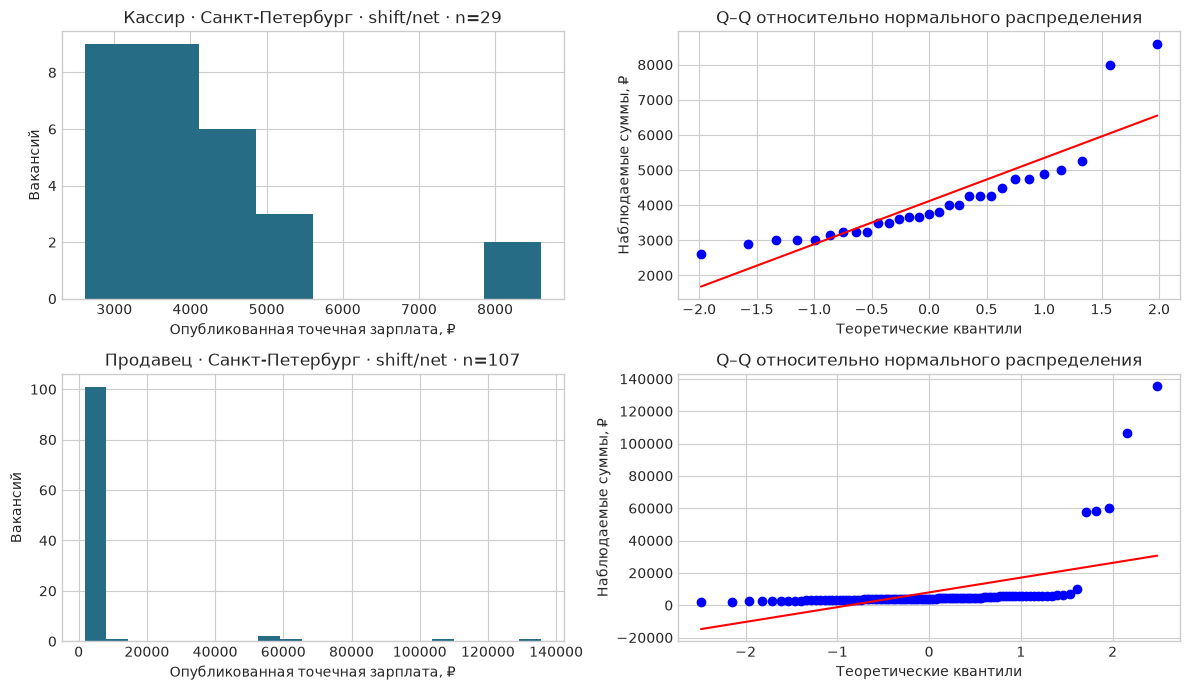

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, profession in enumerate(["Кассир", "Продавец"]):
    city = "Санкт-Петербург"
    case = best.loc[(profession, city)]
    points = base_points.loc[
        base_points["profession_resolved"].eq(profession) & base_points["city_resolved"].eq(city)
        & base_points["salary_unit"].eq(case["salary_unit"]) & base_points["salary_tax"].eq(case["salary_tax"]),
        "salary_midpoint_rub",
    ]
    axes[row, 0].hist(points, color="#276c85", bins="auto")
    axes[row, 0].set_title(f"{profession} · {city} · {case['salary_unit']}/{case['salary_tax']} · n={len(points)}")
    axes[row, 0].set_xlabel("Опубликованная точечная зарплата, ₽")
    axes[row, 0].set_ylabel("Вакансий")
    stats.probplot(points, dist="norm", plot=axes[row, 1])
    axes[row, 1].set(title="Q–Q относительно нормального распределения",
                     xlabel="Теоретические квантили", ylabel="Наблюдаемые суммы, ₽")
fig.tight_layout()
plt.show()


## 7. Проверка исходного решения

**Сохраняем 15 ячеек как пул кандидатов.** Для обучения по исходным критериям
зарплатного класса A готовы два разреза: продавец × Санкт-Петербург
(107 значений, Q1–Q3 = 3 687,50–5 025 ₽) и комплектовщик × Санкт-Петербург
(98 значений, 4 100–5 093,75 ₽). Оба — оплата за смену на руки. Ещё у пяти ячеек
есть не менее 30 сопоставимых точек, но требуется работа по исходному рейтингу.
У восьми ячеек порог в 30 точек не достигается ни в одном сопоставимом разрезе.

**Первый эксперимент.** У кассира × Санкт-Петербург 777 вакансий и 419 точечных
зарплат, из которых 29 относятся к одному явно указанному периоду и налоговой
базе (смена, на руки). Из 122 распознанных зарплат этого разреза 93 односторонние
вилки. Пригодность для запуска по исходным порогам пока не подтверждается.
Его p ≈ 0,0166 и p после Холма ≈ 0,0996. План первого эксперимента можно начать
с уже согласованной альтернативы, продавца × Санкт-Петербург, на сменной
оплате. Для месячной модели потребуется подтвердить период оплаты, налоговую
базу и объём пригодных точек. В снимке у всех 15 ячеек крупнейший сопоставимый
разрез — «за смену на руки».

**Форма и диапазон.** Для точечной цели H₀ отвергнута в 21 из 23 проверенных
разрезов при α = 0,05 и в 17 из 23 после Холма. Внутри утверждённого пула
все 7 разрезов с n ≥ 30 отклоняют H₀ после Холма. Все пять исходных разрезов
зарплатного класса A, включая трёх курьеров, отклоняют H₀ после Холма.
Эмпирический Q1–Q3 остаётся применим как диапазон «в рынке» внутри
сопоставимого разреза. Повторы могут менять долю наблюдений внутри включительного
интервала относительно 50%. Q1–Q3 на малых группах приводится как описание снимка.

У вахты есть шесть диагностик с 20–29 точками. В удалённой когорте ни одна группа
с определённым городом, профессией, периодом и налоговой базой не набрала 20 точек.
Курьеры остаются резервом для отдельного эксперимента по сменной оплате.
